<a href="https://colab.research.google.com/github/hesrodrigo/PUSL3205-LLM-GenAI-Practical-Portfolio/blob/main/Lab-01-Machine-Learning/notebooks/Lab_01_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import re
import os
import zipfile
import requests
from io import BytesIO

In [3]:
dataset_url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
response = requests.get(dataset_url)
if response.status_code == 200:
  print("Dataset download successfully")
else:
  print("Dataset download failed!")

Dataset download successfully


In [4]:
# Cell extracting
os.makedirs("sentiment_dataset", exist_ok=True)
with zipfile.ZipFile(BytesIO(response.content), "r") as zip_ref:
  zip_ref.extractall("sentiment_dataset")
print("Dataset extrected successfully")

print("\nAvailable dataset files:")
for file in os.listdir("sentiment_dataset"):
  print(file)

Dataset extrected successfully

Available dataset files:
__MACOSX
sentiment labelled sentences


In [5]:
nested_path = "sentiment_dataset/sentiment labelled sentences"
print("Filles inside the dataset folder:\n")
for file in os.listdir(nested_path):
  print(file)

Filles inside the dataset folder:

.DS_Store
amazon_cells_labelled.txt
yelp_labelled.txt
imdb_labelled.txt
readme.txt


In [6]:
dataset_path = "sentiment_dataset/sentiment labelled sentences"
dataset_files = [ "amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]
dataframes = []

#Loading the dataset
for file in dataset_files:
  file_path = os.path.join(dataset_path, file)
  records = []
  with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
      line = line.strip()

      if line:
        text, sentiment = line.rsplit("\t", 1)

        records.append({"text": text, "sentiment": int(sentiment)})
  df = pd.DataFrame(records)
  df["source"] = file.replace("_labelled.txt", "")
  dataframes.append(df)
data = pd.concat(dataframes, ignore_index=True)
print("Dataset loaded successfully")
print("Shape of the dataset", data.shape)




Dataset loaded successfully
Shape of the dataset (3000, 3)


In [7]:
data.head()

,text,sentiment,source
0,So there is no way for me to plug it in here i...,0,amazon_cells
1,"Good case, Excellent value.",1,amazon_cells
2,Great for the jawbone.,1,amazon_cells
3,Tied to charger for conversations lasting more...,0,amazon_cells
4,The mic is great.,1,amazon_cells


In [8]:
print(data["source"].value_counts())
print("\nSentiment distribution")
print(data["sentiment"].value_counts())

source
amazon_cells    1000
imdb            1000
yelp            1000
Name: count, dtype: int64

Sentiment distribution
sentiment
0    1500
1    1500
Name: count, dtype: int64


In [9]:
#Checking
print("Dataset shape:", data.shape)
print("\nColumn names :")
print(data.columns.tolist())
print("\nReviews from each source:")
print(data["source"].value_counts())
print("\nSentiment distribution:")
print(data["sentiment"].value_counts())
print("\nMissing values:")
print(data.isnull().sum())

Dataset shape: (3000, 3)

Column names :
['text', 'sentiment', 'source']

Reviews from each source:
source
amazon_cells    1000
imdb            1000
yelp            1000
Name: count, dtype: int64

Sentiment distribution:
sentiment
0    1500
1    1500
Name: count, dtype: int64

Missing values:
text         0
sentiment    0
source       0
dtype: int64


In [10]:
# Investigating the dataset record counts
for file in dataset_files:
  file_path = os.path.join(dataset_path, file)
  with open(file_path, "r", encoding="utf-8") as f:
    lines = f.readlines()
  total_lines = len(lines)
  non_empty_lines = sum(1 for line in lines if line.strip())
  empty_lines = total_lines - non_empty_lines
  print(f"\nFile: {file}")
  print("Total lines:", total_lines)
  print("Non-empty lines:", non_empty_lines)
  print("Empty lines", empty_lines)


File: amazon_cells_labelled.txt
Total lines: 1000
Non-empty lines: 1000
Empty lines 0

File: imdb_labelled.txt
Total lines: 1000
Non-empty lines: 1000
Empty lines 0

File: yelp_labelled.txt
Total lines: 1000
Non-empty lines: 1000
Empty lines 0


Basic Text Preprocessing

In [11]:
import re
def preprocess_text(text):
  text=text.lower()
  text = re.sub(r'[^a-z0-9\s]', '',text)
  text=re.sub(r'\s+', '',text).strip()
  return text
data["clean_text"] = data["text"].apply(preprocess_text)
print("Text preprocessing done")


Text preprocessing done


In [12]:
# Comapring original and the preprocessed
comparison = data[["text", "clean_text"]].head(10)
comparison

,text,clean_text
0,So there is no way for me to plug it in here i...,sothereisnowayformetoplugitinhereintheusunless...
1,"Good case, Excellent value.",goodcaseexcellentvalue
2,Great for the jawbone.,greatforthejawbone
3,Tied to charger for conversations lasting more...,tiedtochargerforconversationslastingmorethan45...
4,The mic is great.,themicisgreat
5,I have to jiggle the plug to get it to line up...,ihavetojiggletheplugtogetittolineuprighttogetd...
6,If you have several dozen or several hundred c...,ifyouhaveseveraldozenorseveralhundredcontactst...
7,If you are Razr owner...you must have this!,ifyouarerazrowneryoumusthavethis
8,"Needless to say, I wasted my money.",needlesstosayiwastedmymoney
9,What a waste of money and time!.,whatawasteofmoneyandtime


In [13]:
print("Original data shape", data.shape)
print("New dataset columns")
print(data.columns.tolist())
print("\nMissing values in clean_text")
print(data["clean_text"].isnull().sum())

Original data shape (3000, 4)
New dataset columns
['text', 'sentiment', 'source', 'clean_text']

Missing values in clean_text
0


Exploring the Text Data


In [15]:
print("Positive reviews")
display(data[data["sentiment"]==1][["text", "clean_text"]].head(5))

print("\nNegative Reviews")
display(data[data["sentiment"]==0][["text", "clean_text"]].head(5))

Positive reviews


,text,clean_text
1,"Good case, Excellent value.",goodcaseexcellentvalue
2,Great for the jawbone.,greatforthejawbone
4,The mic is great.,themicisgreat
7,If you are Razr owner...you must have this!,ifyouarerazrowneryoumusthavethis
10,And the sound quality is great.,andthesoundqualityisgreat



Negative Reviews


,text,clean_text
0,So there is no way for me to plug it in here i...,sothereisnowayformetoplugitinhereintheusunless...
3,Tied to charger for conversations lasting more...,tiedtochargerforconversationslastingmorethan45...
5,I have to jiggle the plug to get it to line up...,ihavetojiggletheplugtogetittolineuprighttogetd...
6,If you have several dozen or several hundred c...,ifyouhaveseveraldozenorseveralhundredcontactst...
8,"Needless to say, I wasted my money.",needlesstosayiwastedmymoney


In [20]:
import re

data["clean_text"] = data["text"].apply(
    lambda text: re.sub(
        r'\s+', ' ',
        re.sub(r'[^a-z\s]', ' ', str(text).lower())
    ).strip()
)

data[["text", "clean_text"]].head()

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


In [21]:
print("Dataset shape:", data.shape)
print("Missing values:", data["clean_text"].isnull().sum())
print("\nCleaned text examples:")
print(data["clean_text"].head(5))

Dataset shape: (3000, 5)
Missing values: 0

Cleaned text examples:
0    so there is no way for me to plug it in here i...
1                            good case excellent value
2                                great for the jawbone
3    tied to charger for conversations lasting more...
4                                     the mic is great
Name: clean_text, dtype: object


In [22]:
from collections import Counter
all_words = "".join(data["clean_text"]).split()
word_counts = Counter(all_words)
print("Top 20 most frequently occuring words")
print(word_counts.most_common(20))


Top 20 most frequently occuring words
[('the', 1499), ('and', 1112), ('a', 854), ('is', 741), ('to', 662), ('of', 614), ('i', 580), ('was', 563), ('it', 489), ('this', 455), ('in', 376), ('for', 316), ('that', 293), ('t', 278), ('not', 271), ('with', 268), ('s', 255), ('my', 219), ('on', 210), ('very', 202)]


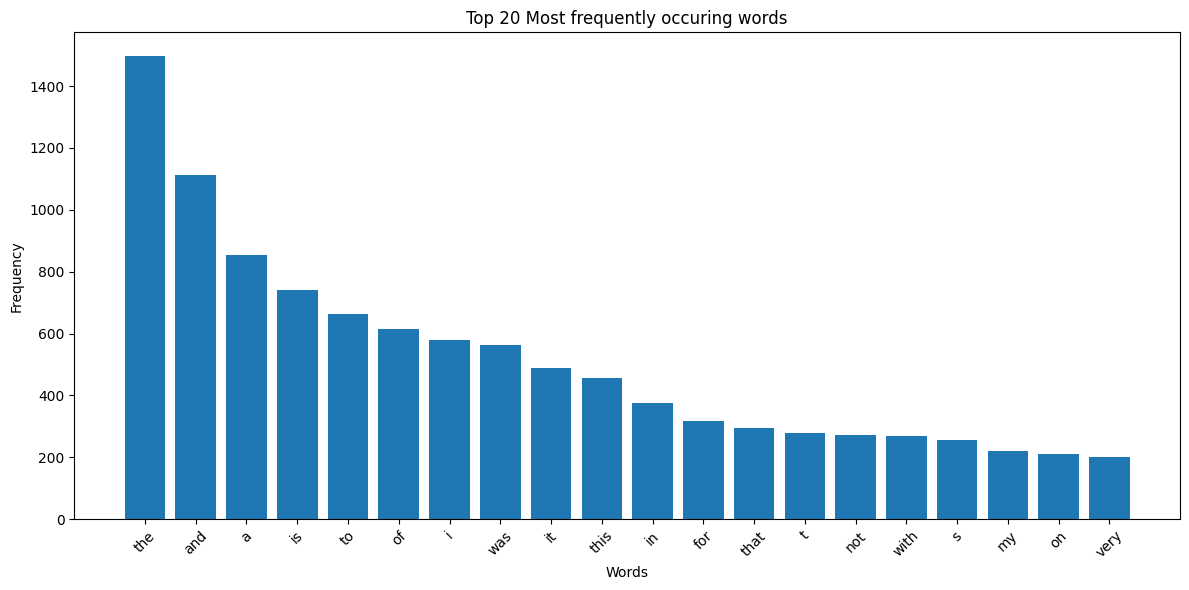

In [24]:
import matplotlib.pyplot as plt
top_words = word_counts.most_common(20)
words = [word for word, count in top_words]
frequencies = [count for word, count in top_words]
plt.figure(figsize=(12,6))
plt.bar(words, frequencies)
plt.title("Top 20 Most frequently occuring words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Stop-word removal

In [30]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
important_words = {'not', 'no', 'nor',"don't", 'never'}
stop_words = stop_words - important_words
print("Total stop words", len(stop_words))
print("\nSample stop words")
print(sorted(stop_words)[:20])

Total stop words 194

Sample stop words
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [31]:
print("Important negative words preserved:")

print({'not', 'no', 'nor', "don't", 'never'} & stop_words)

print("\nCheck whether negative words remain excluded:")

print({'not', 'no', 'nor', "don't", 'never'}.isdisjoint(stop_words))

Important negative words preserved:
set()

Check whether negative words remain excluded:
True


In [32]:

data["filtered_text"] = data["clean_text"].apply(
    lambda text: " ".join(
        word for word in text.split()
        if word not in stop_words
    )
)

display(data[["clean_text", "filtered_text"]].head(10))


,clean_text,filtered_text
0,so there is no way for me to plug it in here i...,no way plug us unless go converter
1,good case excellent value,good case excellent value
2,great for the jawbone,great jawbone
3,tied to charger for conversations lasting more...,tied charger conversations lasting minutes maj...
4,the mic is great,mic great
5,i have to jiggle the plug to get it to line up...,jiggle plug get line right get decent volume
6,if you have several dozen or several hundred c...,several dozen several hundred contacts imagine...
7,if you are razr owner you must have this,razr owner must
8,needless to say i wasted my money,needless say wasted money
9,what a waste of money and time,waste money time


In [33]:

print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data["filtered_text"].isnull().sum())

print("\nNegative word preservation check:")

negative_words = {'not', 'no', 'nor', "don't", 'never'}

for word in negative_words:
    print(f"{word}: {word not in stop_words}")

print("\nFiltered text examples:")
print(data["filtered_text"].head())


Dataset shape: (3000, 6)

Missing values:
0

Negative word preservation check:
never: True
don't: True
not: True
nor: True
no: True

Filtered text examples:
0                   no way plug us unless go converter
1                            good case excellent value
2                                        great jawbone
3    tied charger conversations lasting minutes maj...
4                                            mic great
Name: filtered_text, dtype: object


In [34]:
from sklearn.model_selection import train_test_split

# Features and target
X = data["filtered_text"]
y = data["sentiment"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Data Split")
print("--------------------------------")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training and Testing Data Split
--------------------------------
Training samples: 2400
Testing samples: 600

Training sentiment distribution:
sentiment
1    1200
0    1200
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
1    300
0    300
Name: count, dtype: int64


In [35]:

from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)
print("Bag of Words Vectorization")

print("Training data shape:", X_train_bow.shape)
print("Testing data shape:", X_test_bow.shape)
print("\nTotal vocabulary size:")
print(len(bow_vectorizer.get_feature_names_out()))
print("\nFirst 20 vocabulary words:")
print(bow_vectorizer.get_feature_names_out()[:20])


Bag of Words Vectorization
Training data shape: (2400, 4349)
Testing data shape: (600, 4349)

Total vocabulary size:
4349

First 20 vocabulary words:
['aailiyah' 'abandoned' 'abhor' 'ability' 'able' 'abound' 'abroad'
 'absolute' 'absolutel' 'absolutely' 'absolutley' 'abstruse' 'abysmal'
 'ac' 'academy' 'accents' 'accept' 'acceptable' 'access' 'accessable']


In [36]:
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data[["clean_text", "filtered_text"]].isnull().sum())

print("\nOriginal text vs filtered text:")
display(data[["text", "clean_text", "filtered_text"]].head(10))

print("\nCheck important negative words:")
negative_words = {'not', 'no', 'nor', "don't", 'never'}
print("Negative words preserved in stop-word list:",
      negative_words.isdisjoint(stop_words))

Dataset shape: (3000, 6)

Missing values:
clean_text       0
filtered_text    0
dtype: int64

Original text vs filtered text:


,text,clean_text,filtered_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...,no way plug us unless go converter
1,"Good case, Excellent value.",good case excellent value,good case excellent value
2,Great for the jawbone.,great for the jawbone,great jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...,tied charger conversations lasting minutes maj...
4,The mic is great.,the mic is great,mic great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...,jiggle plug get line right get decent volume
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...,several dozen several hundred contacts imagine...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this,razr owner must
8,"Needless to say, I wasted my money.",needless to say i wasted my money,needless say wasted money
9,What a waste of money and time!.,what a waste of money and time,waste money time



Check important negative words:
Negative words preserved in stop-word list: True


In [37]:

from collections import Counter

# Combine all filtered text
all_filtered_words = " ".join(data["filtered_text"]).split()
filtered_word_freq = Counter(all_filtered_words)


top_20_filtered = filtered_word_freq.most_common(20)

print("Top 20 most frequently occurring words after stop-word removal:")
print(top_20_filtered)


Top 20 most frequently occurring words after stop-word removal:
[('not', 306), ('good', 231), ('great', 210), ('movie', 182), ('phone', 168), ('film', 163), ('one', 146), ('food', 126), ('like', 125), ('place', 114), ('time', 112), ('service', 108), ('bad', 103), ('really', 103), ('well', 92), ('would', 87), ('no', 83), ('best', 78), ('even', 77), ('ever', 76)]


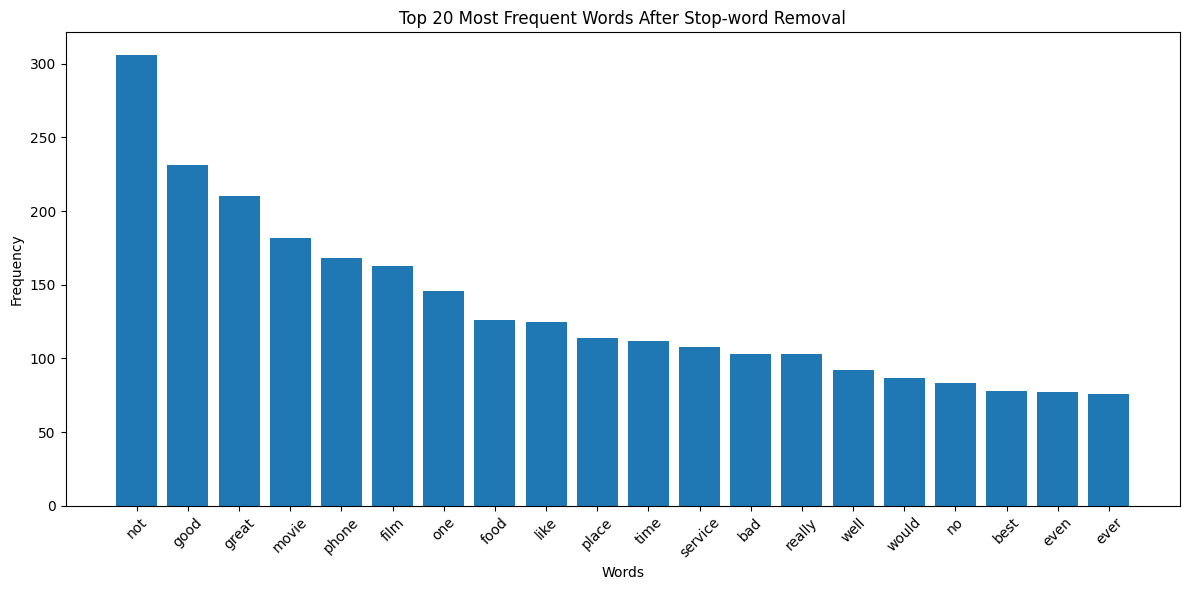

In [38]:

import matplotlib.pyplot as plt

words = [word for word, count in top_20_filtered]
frequencies = [count for word, count in top_20_filtered]

plt.figure(figsize=(12, 6))

plt.bar(words, frequencies)

plt.title("Top 20 Most Frequent Words After Stop-word Removal")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Sentiment distribution:
sentiment
0    1500
1    1500
Name: count, dtype: int64


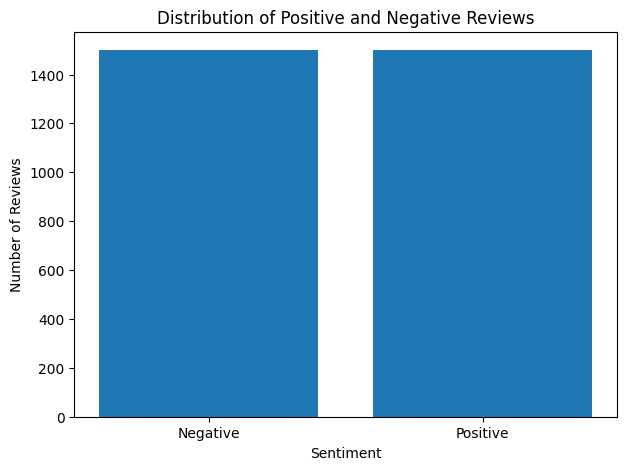

In [39]:

import matplotlib.pyplot as plt

# Count positive and negative reviews
sentiment_counts = data["sentiment"].value_counts().sort_index()

print("Sentiment distribution:")
print(sentiment_counts)

# Plot the distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ["Negative", "Positive"],
    [sentiment_counts.get(0, 0), sentiment_counts.get(1, 0)]
)

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


In [40]:

from sklearn.model_selection import train_test_split

# Features (input text)
X = data["filtered_text"]

# Target (sentiment labels)
y = data["sentiment"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training samples: 2400
Testing samples: 600

Training sentiment distribution:
sentiment
1    1200
0    1200
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
1    300
0    300
Name: count, dtype: int64


In [41]:

from sklearn.feature_extraction.text import CountVectorizer

# Initialise the CountVectorizer
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)
print("Training BoW shape:", X_train_bow.shape)
print("Testing BoW shape:", X_test_bow.shape)

print("\nNumber of unique vocabulary words:",
      len(vectorizer.vocabulary_))

print("\nSample vocabulary:")
print(list(vectorizer.vocabulary_.keys())[:20])


Training BoW shape: (2400, 4349)
Testing BoW shape: (600, 4349)

Number of unique vocabulary words: 4349

Sample vocabulary:
['loved', 'mussels', 'cooked', 'wine', 'reduction', 'duck', 'tender', 'potato', 'dishes', 'delicious', 'staff', 'great', 'ambiance', 'service', 'give', 'no', 'stars', 'paolo', 'sorrentino', 'written']


In [42]:

from sklearn.linear_model import LogisticRegression

# Initialise the Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train_bow, y_train)

print("Model training completed successfully!")

# Generate predictions on testing data
y_pred = model.predict(X_test_bow)

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)



Model training completed successfully!

First 10 predictions:
[1 1 0 1 0 1 1 0 0 1]

First 10 actual labels:
[1 1 0 1 0 1 1 1 0 1]


Model Accuracy: 82.83 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.84      0.83       300
    Positive       0.83      0.82      0.83       300

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600


Confusion Matrix:
[[251  49]
 [ 54 246]]


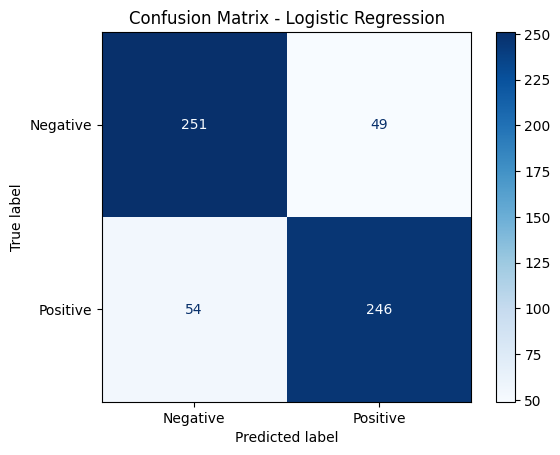

In [43]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Visualise confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


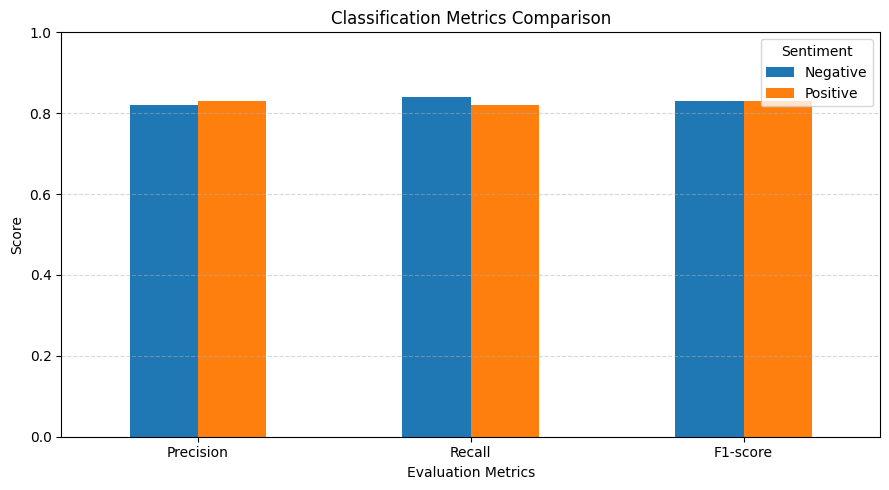

In [44]:

import pandas as pd
import matplotlib.pyplot as plt

# Store classification metrics
metrics = {
    "Negative": [0.82, 0.84, 0.83],
    "Positive": [0.83, 0.82, 0.83]
}

metrics_df = pd.DataFrame(
    metrics,
    index=["Precision", "Recall", "F1-score"]
)

# Plot comparison
metrics_df.plot(kind="bar", figsize=(9, 5))

plt.title("Classification Metrics Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [46]:

# Check how new sentences are processed

print("PREPROCESSING RESULTS")
print("=" * 70)

for original, cleaned in zip(new_sentences, cleaned_sentences):
    print("Original:", original)
    print("Cleaned: ", cleaned)
    print("-" * 70)


PREPROCESSING RESULTS
Original: This product is absolutely amazing and I love it
Cleaned:  thisproductisabsolutelyamazingandiloveit
----------------------------------------------------------------------
Original: The service was terrible and I hated the experience
Cleaned:  theservicewasterribleandihatedtheexperience
----------------------------------------------------------------------
Original: The food was delicious and the staff were very friendly
Cleaned:  thefoodwasdeliciousandthestaffwereveryfriendly
----------------------------------------------------------------------
Original: This movie was boring and a complete waste of time
Cleaned:  thismoviewasboringandacompletewasteoftime
----------------------------------------------------------------------
Original: I am not happy with this product
Cleaned:  iamnothappywiththisproduct
----------------------------------------------------------------------
Original: The quality is excellent and I would definitely recommend it
Cleaned:  

Testing the model with new sentences

In [48]:
# Test the trained model with new, unseen sentences

new_sentences = [
    "This product is absolutely amazing and I love it",
    "The service was terrible and I hated the experience",
    "The food was delicious and the staff were very friendly",
    "This movie was boring and a complete waste of time",
    "I am not happy with this product",
    "The quality is excellent and I would definitely recommend it"
]

# Apply the same preprocessing used during training
cleaned_sentences = [preprocess_text(sentence) for sentence in new_sentences]

# Convert sentences into Bag-of-Words representations
new_sentences_bow = vectorizer.transform(cleaned_sentences)

# Predict sentiment
predictions = model.predict(new_sentences_bow)

# Display predictions
for sentence, prediction in zip(new_sentences, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", sentence)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This product is absolutely amazing and I love it
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The service was terrible and I hated the experience
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Predicted Sentiment: Negative
------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Predicted Sentiment: Negative
------------------------------------------------------------
Review: I am not happy with this product
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Predicted Sentiment: Negative
------------------------------------------------------------


In [49]:

# Check whether new sentences contain recognised vocabulary

print("BAG-OF-WORDS DIAGNOSTICS")
print("=" * 70)

for sentence, bow_vector in zip(new_sentences, new_sentences_bow):
    print("Review:", sentence)
    print("Recognised words:", bow_vector.nnz)
    print("-" * 70)


BAG-OF-WORDS DIAGNOSTICS
Review: This product is absolutely amazing and I love it
Recognised words: 0
----------------------------------------------------------------------
Review: The service was terrible and I hated the experience
Recognised words: 0
----------------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Recognised words: 0
----------------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Recognised words: 0
----------------------------------------------------------------------
Review: I am not happy with this product
Recognised words: 0
----------------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Recognised words: 0
----------------------------------------------------------------------


In [50]:

# Examine the model's confidence for each prediction

probabilities = model.predict_proba(new_sentences_bow)

for sentence, probability in zip(new_sentences, probabilities):
    print("Review:", sentence)
    print("Negative probability:", round(probability[0], 4))
    print("Positive probability:", round(probability[1], 4))
    print("-" * 60)


Review: This product is absolutely amazing and I love it
Negative probability: 0.5608
Positive probability: 0.4392
------------------------------------------------------------
Review: The service was terrible and I hated the experience
Negative probability: 0.5608
Positive probability: 0.4392
------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Negative probability: 0.5608
Positive probability: 0.4392
------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Negative probability: 0.5608
Positive probability: 0.4392
------------------------------------------------------------
Review: I am not happy with this product
Negative probability: 0.5608
Positive probability: 0.4392
------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Negative probability: 0.5608
Positive probability: 0.43

In [51]:


import re
import string

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]


    return ' '.join(tokens)

In [52]:
# Apply improved preprocessing to training and testing data

X_train_clean = X_train.apply(preprocess_text)
X_test_clean = X_test.apply(preprocess_text)

print("Sample cleaned training sentences:")
print(X_train_clean.head())

Sample cleaned training sentences:
2103    loved mussels cooked wine reduction duck tende...
2368                           staff great ambiance great
2412                                service give no stars
1928    paolo sorrentino written wonderful story lonel...
1590                                  believe even sequel
Name: filtered_text, dtype: object


In [53]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X_train_bow = vectorizer.fit_transform(X_train_clean)
X_test_bow = vectorizer.transform(X_test_clean)

print("Training BoW shape:", X_train_bow.shape)
print("Testing BoW shape:", X_test_bow.shape)

Training BoW shape: (2400, 4349)
Testing BoW shape: (600, 4349)


In [54]:
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_bow, y_train)

print("Model retrained successfully!")

Model retrained successfully!


In [55]:
# Check whether unseen sentences are recognised

cleaned_sentences = [preprocess_text(sentence) for sentence in new_sentences]

new_sentences_bow = vectorizer.transform(cleaned_sentences)

for sentence, bow_vector in zip(new_sentences, new_sentences_bow):
    print("Review:", sentence)
    print("Recognised words:", bow_vector.nnz)
    print("-" * 60)

Review: This product is absolutely amazing and I love it
Recognised words: 4
------------------------------------------------------------
Review: The service was terrible and I hated the experience
Recognised words: 4
------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Recognised words: 4
------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Recognised words: 5
------------------------------------------------------------
Review: I am not happy with this product
Recognised words: 3
------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Recognised words: 5
------------------------------------------------------------


In [56]:
# Predict sentiment using the corrected preprocessing

predictions = model.predict(new_sentences_bow)

for sentence, prediction in zip(new_sentences, predictions):

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", sentence)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This product is absolutely amazing and I love it
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The service was terrible and I hated the experience
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Predicted Sentiment: Positive
------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Predicted Sentiment: Negative
------------------------------------------------------------
Review: I am not happy with this product
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Predicted Sentiment: Positive
------------------------------------------------------------


In [57]:
# Test the trained model with new, unseen sentences

new_sentences = [
    "This product is absolutely amazing and I love it",
    "The service was terrible and I hated the experience",
    "The food was delicious and the staff were very friendly",
    "This movie was boring and a complete waste of time",
    "I am not happy with this product",
    "The quality is excellent and I would definitely recommend it"
]

# Apply the same preprocessing used during training
cleaned_sentences = [preprocess_text(sentence) for sentence in new_sentences]

# Convert sentences into Bag-of-Words representations
new_sentences_bow = vectorizer.transform(cleaned_sentences)

# Predict sentiment
predictions = model.predict(new_sentences_bow)

# Display predictions
for sentence, prediction in zip(new_sentences, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", sentence)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This product is absolutely amazing and I love it
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The service was terrible and I hated the experience
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The food was delicious and the staff were very friendly
Predicted Sentiment: Positive
------------------------------------------------------------
Review: This movie was boring and a complete waste of time
Predicted Sentiment: Negative
------------------------------------------------------------
Review: I am not happy with this product
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The quality is excellent and I would definitely recommend it
Predicted Sentiment: Positive
------------------------------------------------------------


In [58]:

# Evaluate the corrected Logistic Regression model

from sklearn.metrics import accuracy_score, classification_report

# Generate predictions on the testing dataset
y_pred = model.predict(X_test_bow)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("UPDATED MODEL EVALUATION")
print("=" * 50)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Generate classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))


UPDATED MODEL EVALUATION
Model Accuracy: 82.83%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.84      0.83       300
    Positive       0.83      0.82      0.83       300

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600



## 1. Model Performance

After training the Logistic Regression model, it achieved an accuracy of **82.83%** on the test dataset.

The classification report showed the following results:

- Negative sentiment: Precision – 0.82, Recall – 0.84, F1-score – 0.83.
- Positive sentiment: Precision – 0.83, Recall – 0.82, F1-score – 0.83.

From these results, we can see that the model performs quite well in identifying both positive and negative reviews. The confusion matrix also shows that most of the reviews were classified correctly.

## 2. Testing with New Sentences

After training the model, I tested it using six new sentences to see how well it could predict the sentiment of reviews it had not seen before.

Initially, there was an issue with the preprocessing function, which caused the model to recognise zero words from the new sentences. After correcting this issue, the model was able to recognise the words and correctly classify all six example sentences.

## 3. Limitations

Although the model performed reasonably well, there are some limitations:

- It does not fully understand the meaning or context of sentences.
- It may have difficulty identifying sarcasm or complex expressions.
- It cannot properly recognise words that were not included in the training vocabulary.
- It may sometimes struggle with sentences containing negative expressions.

## 4. Conclusion

Through this practical, I gained a better understanding of how Natural Language Processing can be used to perform sentiment analysis.

I learned how to preprocess text data, convert sentences into numerical features using the Bag-of-Words technique, and train a Logistic Regression model to classify sentiments.

The model achieved an accuracy of 82.83%, which shows that it can identify positive and negative reviews with reasonably good performance.

Overall, this practical helped me understand the basic steps involved in building and evaluating a machine learning model for text classification.
